In [1]:
import pandas as pd

url = "https://meteofrance.s3.sbg.io.cloud.ovh.net/data/REF_CC/SIM/QUOT_SIM2_2024.csv.gz"

# Lire seulement les 5 000 premières lignes (quelques secondes)
extrait = pd.read_csv(url, sep=";", nrows=5000)

print(extrait.columns.tolist())
extrait.head()

['LAMBX', 'LAMBY', 'DATE', 'PRENEI', 'PRELIQ', 'T', 'FF', 'Q', 'DLI', 'SSI', 'HU', 'EVAP', 'ETP', 'PE', 'SWI', 'SSWI_10J', 'DRAINC', 'RUNC', 'RESR_NEIGE', 'RESR_NEIGE6', 'HTEURNEIGE', 'HTEURNEIGE6', 'HTEURNEIGEX', 'SNOW_FRAC', 'ECOULEMENT', 'WG_RACINE', 'WGI_RACINE', 'TINF_H', 'TSUP_H']


,LAMBX,LAMBY,DATE,PRENEI,PRELIQ,T,FF,Q,DLI,SSI,...,RESR_NEIGE6,HTEURNEIGE,HTEURNEIGE6,HTEURNEIGEX,SNOW_FRAC,ECOULEMENT,WG_RACINE,WGI_RACINE,TINF_H,TSUP_H
0,600,24010,20240101,0.0,19.1,10.5,7.9,7.062,3133.4,212.2,...,0.0,0.0,0.0,0.0,0.0,0.0,0.303,0.0,6.8,13.7
1,600,24010,20240102,0.0,8.4,13.3,12.4,8.313,3224.8,203.1,...,0.0,0.0,0.0,0.0,0.0,0.0,0.310,0.0,12.4,14.3
2,600,24010,20240103,0.0,6.0,11.0,11.3,6.763,2875.1,258.7,...,0.0,0.0,0.0,0.0,0.0,0.0,0.312,0.0,11.0,11.6
3,600,24010,20240104,0.0,14.8,9.7,7.3,6.712,3120.1,155.3,...,0.0,0.0,0.0,0.0,0.0,0.0,0.313,0.0,8.8,12.3
4,600,24010,20240105,0.0,3.1,8.0,5.6,5.557,2874.9,249.2,...,0.0,0.0,0.0,0.0,0.0,0.0,0.318,0.0,5.6,9.8


In [2]:
cols = ["LAMBX", "LAMBY", "DATE", "PRELIQ", "PRENEI"]
print(extrait[cols].head())
print(extrait[["LAMBX", "LAMBY"]].describe().round(0))
print("Type de DATE :", extrait["DATE"].dtype)

   LAMBX  LAMBY      DATE  PRELIQ  PRENEI
0    600  24010  20240101    19.1     0.0
1    600  24010  20240102     8.4     0.0
2    600  24010  20240103     6.0     0.0
3    600  24010  20240104    14.8     0.0
4    600  24010  20240105     3.1     0.0
        LAMBX    LAMBY
count  5000.0   5000.0
mean    797.0  23905.0
std      71.0    219.0
min     600.0  23530.0
25%     760.0  23610.0
50%     840.0  24010.0
75%     840.0  24090.0
max     920.0  24170.0
Type de DATE : int64


In [3]:
import os
import time

dossier = "../data/pluies_annuelles"
os.makedirs(dossier, exist_ok=True)

for annee in range(1982, 2026):
    fichier = f"{dossier}/{annee}.parquet"
    if os.path.exists(fichier):
        continue  # année déjà calculée, on passe

    debut = time.time()
    url = f"https://meteofrance.s3.sbg.io.cloud.ovh.net/data/REF_CC/SIM/QUOT_SIM2_{annee}.csv.gz"
    d = pd.read_csv(url, sep=";", usecols=["LAMBX", "LAMBY", "PRELIQ", "PRENEI"])

    d["pluie"] = d["PRELIQ"] + d["PRENEI"]
    res = d.groupby(["LAMBX", "LAMBY"]).agg(
        pluie_max_jour=("pluie", "max"),
        nb_jours_50mm=("pluie", lambda s: (s >= 50).sum()),
        cumul_annuel=("pluie", "sum"),
    ).reset_index()
    res["annee"] = annee
    res.to_parquet(fichier, index=False)

    print(f"{annee} : {len(res)} points, {round(time.time() - debut)} s")

1982 : 9892 points, 6 s
1983 : 9892 points, 5 s
1984 : 9892 points, 5 s
1985 : 9892 points, 6 s
1986 : 9892 points, 5 s
1987 : 9892 points, 5 s
1988 : 9892 points, 5 s
1989 : 9892 points, 5 s
1990 : 9892 points, 5 s
1991 : 9892 points, 5 s
1992 : 9892 points, 6 s
1993 : 9892 points, 6 s
1994 : 9892 points, 5 s
1995 : 9892 points, 5 s
1996 : 9892 points, 6 s
1997 : 9892 points, 5 s
1998 : 9892 points, 5 s
1999 : 9892 points, 6 s
2000 : 9892 points, 5 s
2001 : 9892 points, 5 s
2002 : 9892 points, 5 s
2003 : 9892 points, 5 s
2004 : 9892 points, 6 s
2005 : 9892 points, 6 s
2006 : 9892 points, 6 s
2007 : 9892 points, 6 s
2008 : 9892 points, 5 s
2009 : 9892 points, 5 s
2010 : 9892 points, 6 s
2011 : 9892 points, 6 s
2012 : 9892 points, 5 s
2013 : 9892 points, 6 s
2014 : 9892 points, 6 s
2015 : 9892 points, 6 s
2016 : 9892 points, 5 s
2017 : 9892 points, 6 s
2018 : 9892 points, 5 s
2019 : 9892 points, 6 s
2020 : 9892 points, 6 s
2021 : 9892 points, 5 s
2022 : 9892 points, 6 s
2023 : 9892 poin

In [5]:
import glob
import geopandas as gpd

# 1. Rassembler les 44 années, puis résumer par point de grille
annuel = pd.concat(pd.read_parquet(f) for f in glob.glob("../data/pluies_annuelles/*.parquet"))
print("Années :", annuel["annee"].nunique())

pluie_pts = annuel.groupby(["LAMBX", "LAMBY"]).agg(
    pluie_max_jour_moy=("pluie_max_jour", "mean"),  # pluie max d'une journée, en moyenne sur les années
    pluie_max_jour_abs=("pluie_max_jour", "max"),   # record absolu sur 44 ans
    nb_jours_50mm_an=("nb_jours_50mm", "mean"),     # nombre moyen de jours ≥ 50 mm par an
    cumul_annuel_moy=("cumul_annuel", "mean"),      # pluie totale moyenne par an
).reset_index()

# 2. Hectomètres -> mètres, Lambert II étendu (27572) -> Lambert-93 (2154)
pts = gpd.GeoDataFrame(
    pluie_pts,
    geometry=gpd.points_from_xy(pluie_pts["LAMBX"] * 100, pluie_pts["LAMBY"] * 100),
    crs="EPSG:27572",
).to_crs(2154)
print("Emprise [lon_min, lat_min, lon_max, lat_max] :", pts.to_crs(4326).total_bounds.round(2))

# 3. Centres des communes (seulement celles qui ont des coordonnées)
df = pd.read_parquet("../data/communes_cible_swi_relief.parquet")
avec_coords = df.dropna(subset=["lon", "lat"])
print("Communes sans coordonnées (exclues de la jointure) :", len(df) - len(avec_coords))

com = gpd.GeoDataFrame(
    avec_coords[["code_commune"]],
    geometry=gpd.points_from_xy(avec_coords["lon"], avec_coords["lat"]),
    crs="EPSG:4326",
).to_crs(2154)

cols_pluie = ["pluie_max_jour_moy", "pluie_max_jour_abs", "nb_jours_50mm_an", "cumul_annuel_moy"]
com = gpd.sjoin_nearest(com, pts[cols_pluie + ["geometry"]], how="left",
                        max_distance=10_000, distance_col="dist_pluie_m")
com = com.drop_duplicates(subset="code_commune")

# 4. Recoller les pluies sur la table complète
df = df.merge(com[["code_commune", "dist_pluie_m"] + cols_pluie], on="code_commune", how="left")

print("Communes sans pluie :", df["pluie_max_jour_moy"].isna().sum(), "/", len(df))
print("Distance moyenne :", round(df["dist_pluie_m"].mean()), "m")
df.groupby("risque_fort")[cols_pluie].mean().round(1)

Années : 44
Emprise [lon_min, lat_min, lon_max, lat_max] : [-4.96 41.34 10.04 51.12]
Communes sans coordonnées (exclues de la jointure) : 102
Communes sans pluie : 104 / 34455
Distance moyenne : 3064 m


,pluie_max_jour_moy,pluie_max_jour_abs,nb_jours_50mm_an,cumul_annuel_moy
risque_fort,,,,
0,39.4,76.2,0.3,910.5
1,48.6,109.4,0.7,884.5


In [6]:
from xgboost import XGBClassifier
from sklearn.model_selection import GroupKFold, cross_validate

df.to_parquet("../data/communes_v2.parquet", index=False)  # sauvegarde

features_v1 = ["swi_moyen", "swi_max", "swi_p90", "part_mois_sature",
               "altitude", "denivele_local", "pente_max_pct", "position_relative"]
features_v2 = features_v1 + cols_pluie

y = df["risque_fort"]
groups = df["codeDepartement"].fillna(df["code_commune"].str[:2])
poids = (y == 0).sum() / (y == 1).sum()

def modele():
    return XGBClassifier(n_estimators=300, max_depth=4, learning_rate=0.05,
                         subsample=0.8, colsample_bytree=0.8,
                         scale_pos_weight=poids, eval_metric="logloss", random_state=42)

scoring = {"roc_auc": "roc_auc", "pr_auc": "average_precision", "recall": "recall"}
resultats = {}
for nom, feats in [("v1 : SWI + relief", features_v1), ("v2 : + pluies extrêmes", features_v2)]:
    res = cross_validate(modele(), df[feats], y, scoring=scoring,
                         groups=groups, cv=GroupKFold(n_splits=5))
    resultats[nom] = {k: res[f"test_{k}"].mean() for k in scoring}

pd.DataFrame(resultats).round(3)

,v1 : SWI + relief,v2 : + pluies extrêmes
roc_auc,0.717,0.731
pr_auc,0.462,0.496
recall,0.580,0.561


      v1     v2  v2 meilleure ?
0  0.491  0.509            True
1  0.486  0.519            True
2  0.305  0.417            True
3  0.612  0.615            True
4  0.419  0.422            True


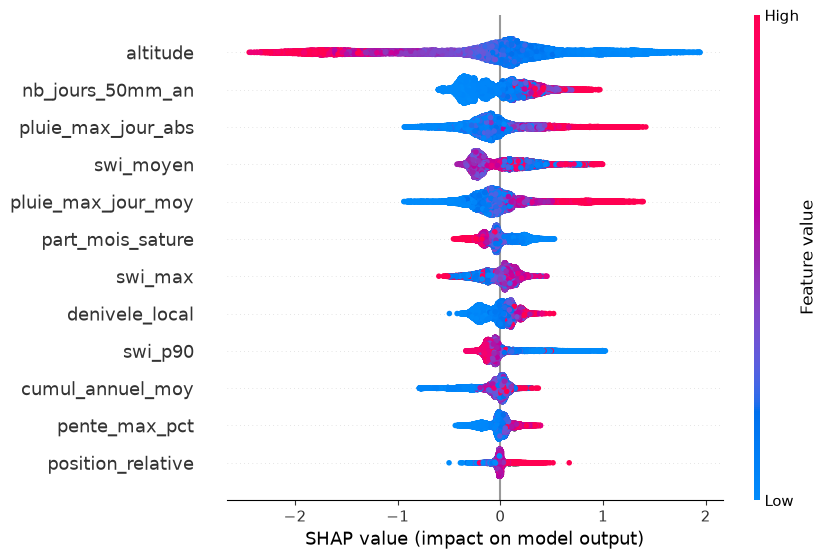

In [7]:
import shap

# 1. PR-AUC groupe par groupe (mêmes 5 groupes de départements)
detail = {}
for nom, feats in [("v1", features_v1), ("v2", features_v2)]:
    res = cross_validate(modele(), df[feats], y, scoring="average_precision",
                         groups=groups, cv=GroupKFold(n_splits=5))
    detail[nom] = res["test_score"]
detail = pd.DataFrame(detail).round(3)
detail["v2 meilleure ?"] = detail["v2"] > detail["v1"]
print(detail)

# 2. SHAP sur le modèle v2
model_v2 = modele().fit(df[features_v2], y)
shap_v2 = shap.TreeExplainer(model_v2)(df[features_v2])
shap.plots.beeswarm(shap_v2, max_display=12)

In [8]:
from sklearn.model_selection import cross_val_predict

df["proba_risque"] = cross_val_predict(
    modele(), df[features_v2], y, groups=groups,
    cv=GroupKFold(n_splits=5), method="predict_proba"
)[:, 1]

cols = ["code_commune", "nom", "codeDepartement", "lon", "lat",
        "risque_fort", "nb_arretes_inond", "proba_risque"] + features_v2
df[cols].to_parquet("../data/predictions_communes.parquet", index=False)
print("Prédictions v2 enregistrées :", len(df))

Prédictions v2 enregistrées : 34455
